# Trực quan hóa tennis — Thành viên C

Notebook này dùng các bảng historical đã được B xác minh. Nó không truy cập `.env`, không gọi API, không tính lại chỉ số nghiệp vụ và không gộp dữ liệu unified/API.

In [1]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'config' / 'project.json').exists())
sys.path.insert(0, str(ROOT))
from src.visualization import (load_contract, load_table, export_figure,
    plot_season_matches, plot_surface_composition, plot_duration_by_surface_format,
    plot_upset_rate_by_surface_format, plot_rank_group_win_rate, plot_ace_rate_by_surface)

TABLES = ROOT / 'reports' / 'tables'
CONTRACT_PATH = TABLES / 'table_contract.json'
FIGURES = ROOT / 'reports' / 'figures'
contract = load_contract(CONTRACT_PATH)
print('Contract version:', contract['version'])
print('Scope: historical hand-off tables only')

Contract version: 1.0.0
Scope: historical hand-off tables only


## Đọc CSV và kiểm tra contract
Mỗi tỷ lệ được giữ ở thang 0–1 cho tới lớp hiển thị.

In [2]:
tables = {name: load_table(name, TABLES, CONTRACT_PATH) for name in [
    'season_summary', 'surface_summary', 'duration_by_surface_format',
    'upsets_by_surface_format', 'rank_group_performance', 'serve_by_surface']}
{name: frame.shape for name, frame in tables.items()}

{'season_summary': (11, 9),
 'surface_summary': (3, 9),
 'duration_by_surface_format': (6, 12),
 'upsets_by_surface_format': (6, 10),
 'rank_group_performance': (5, 6),
 'serve_by_surface': (18, 7)}

## Sáu biểu đồ xuất bản
Mỗi biểu đồ tự gắn nguồn, mẫu số và giới hạn diễn giải. `overwrite=True` chỉ áp dụng cho artifact C có tên ổn định.

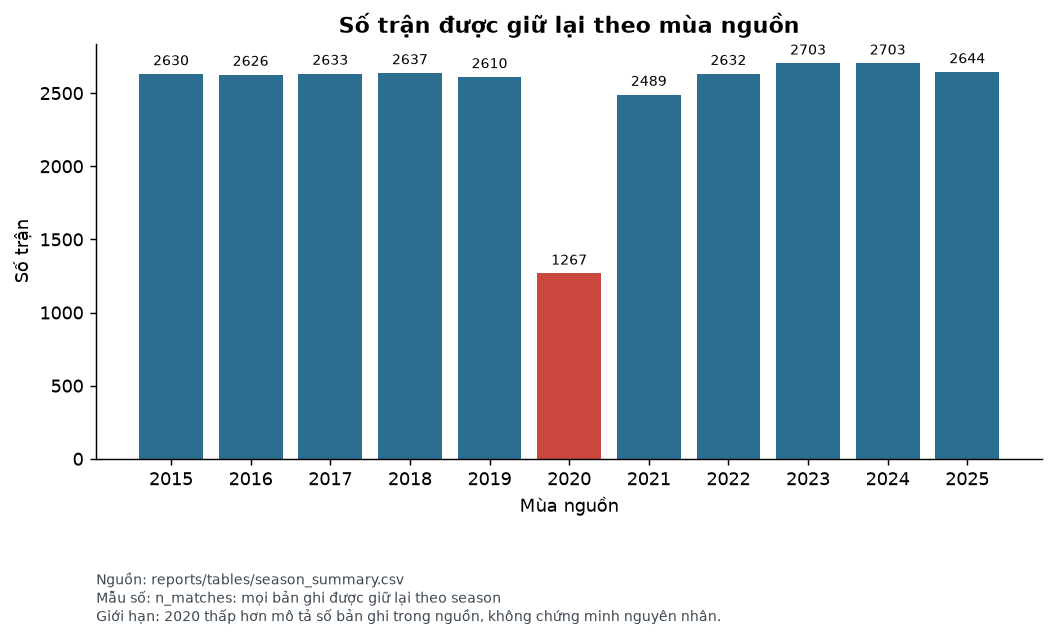

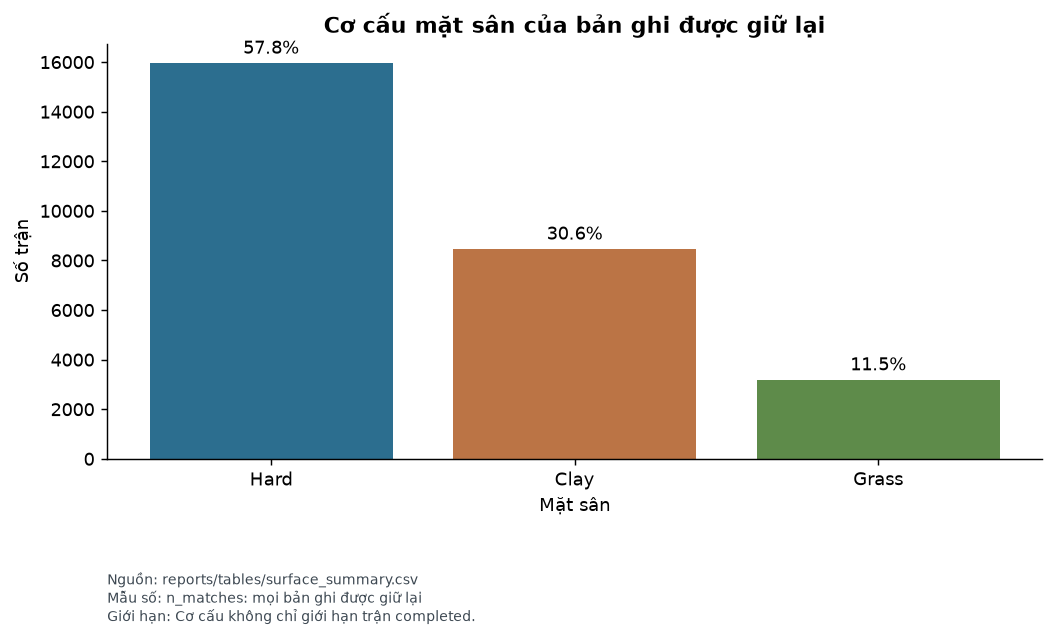

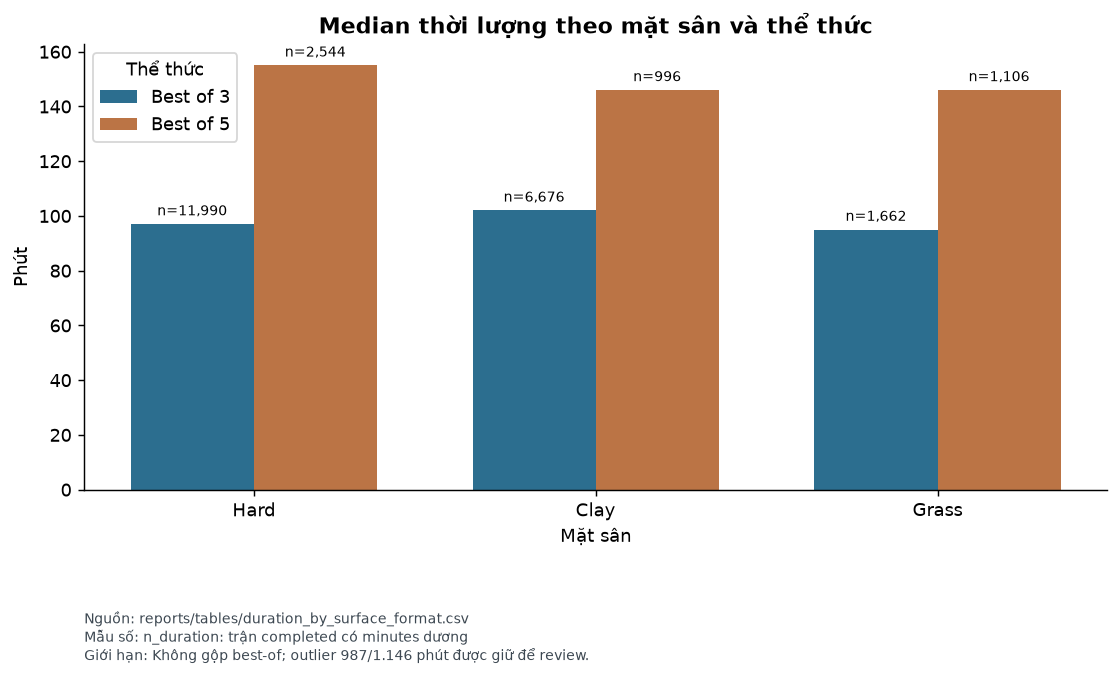

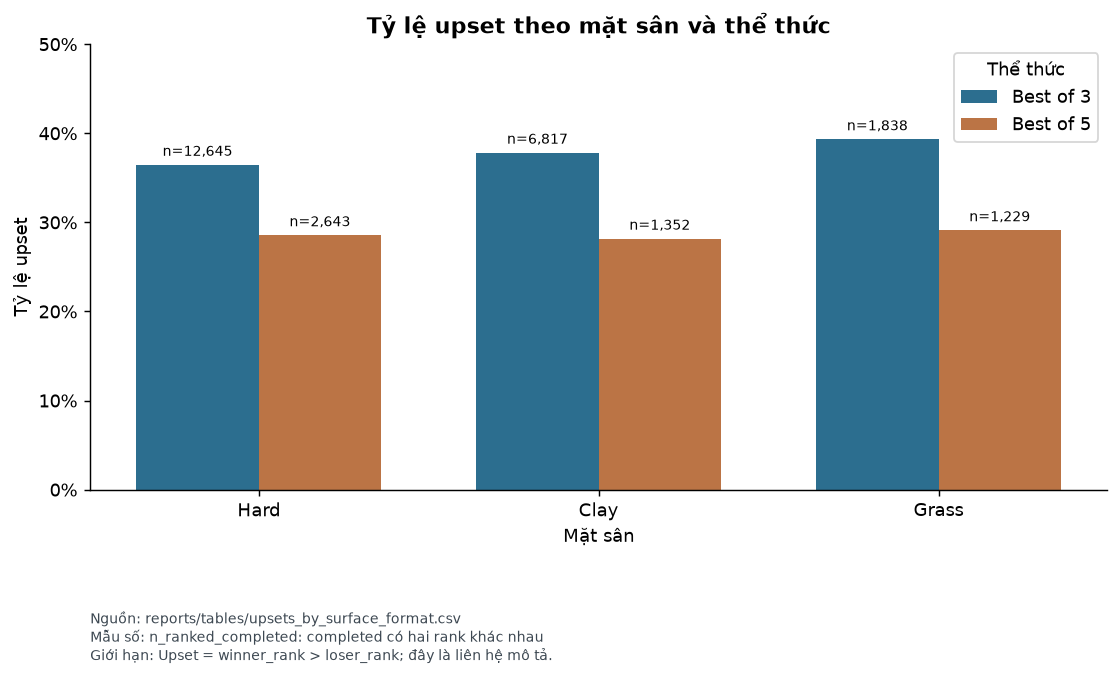

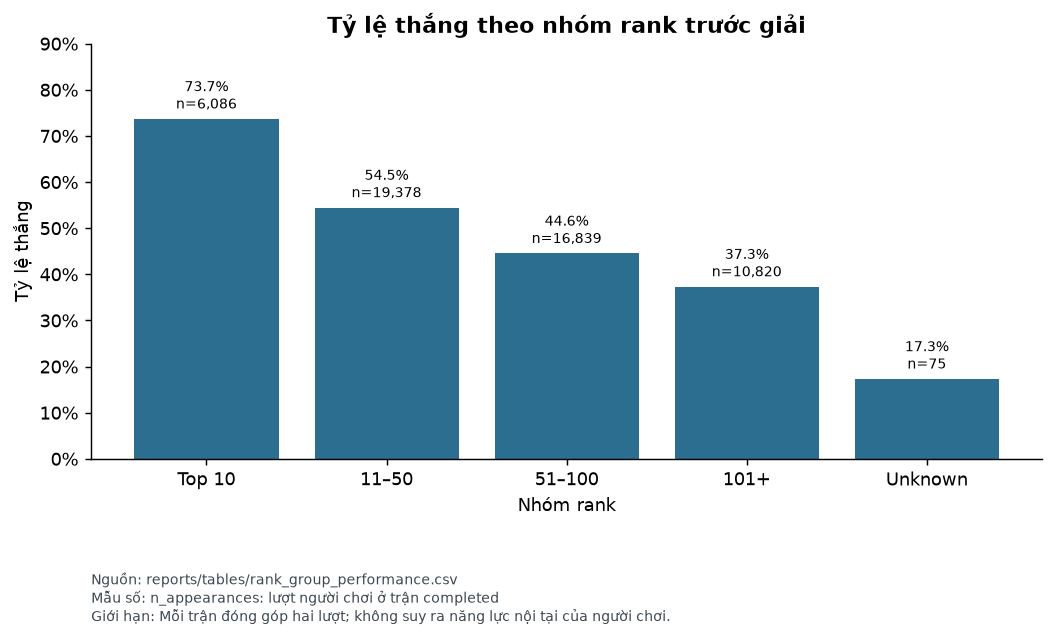

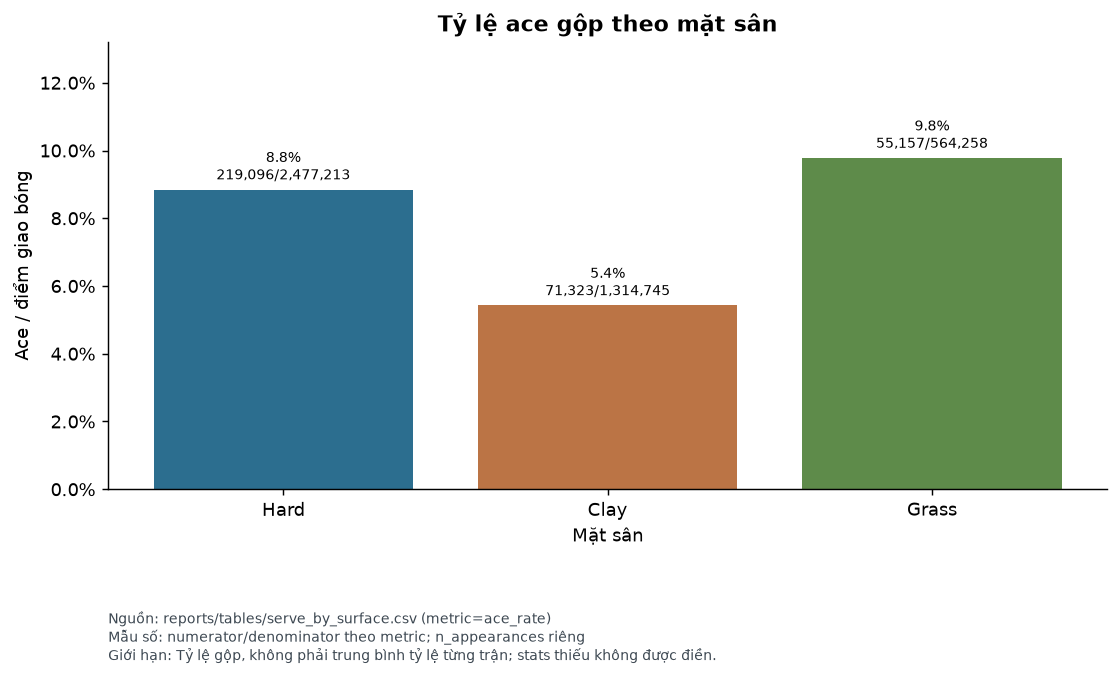

{'season_matches': ('reports/figures/season_matches.png', 'reports/figures/season_matches.svg'), 'surface_composition': ('reports/figures/surface_composition.png', 'reports/figures/surface_composition.svg'), 'duration_surface_format': ('reports/figures/duration_surface_format.png', 'reports/figures/duration_surface_format.svg'), 'upset_surface_format': ('reports/figures/upset_surface_format.png', 'reports/figures/upset_surface_format.svg'), 'rank_group_win_rate': ('reports/figures/rank_group_win_rate.png', 'reports/figures/rank_group_win_rate.svg'), 'ace_rate_surface': ('reports/figures/ace_rate_surface.png', 'reports/figures/ace_rate_surface.svg')}

In [3]:
specs = [
    ('season_matches', plot_season_matches, 'season_summary'),
    ('surface_composition', plot_surface_composition, 'surface_summary'),
    ('duration_surface_format', plot_duration_by_surface_format, 'duration_by_surface_format'),
    ('upset_surface_format', plot_upset_rate_by_surface_format, 'upsets_by_surface_format'),
    ('rank_group_win_rate', plot_rank_group_win_rate, 'rank_group_performance'),
    ('ace_rate_surface', plot_ace_rate_by_surface, 'serve_by_surface'),
]
exports = {}
for stem, plotter, table_name in specs:
    figure = plotter(tables[table_name])
    exports[stem] = export_figure(figure, FIGURES, stem, overwrite=True)
    plt.show()
exports

## Insight và giới hạn
2020 có 1.267 bản ghi so với 2.610 năm 2019; đây không xác định nguyên nhân. So sánh duration luôn tách `best_of` và sử dụng `n_duration`; coverage 2015 thấp. Upset chỉ dùng `n_ranked_completed`; rank chart đo player appearances, mỗi trận completed tạo hai lượt. Ace rate là tỷ lệ gộp trên đúng tử/mẫu của metric. Chi tiết truy vết tại `reports/insights.md`.